[  1/123] kappa =  300.0   T =  86.910   C'(pi) = +3.5201e-04 /day   2 fixed pts      4.4s
[  2/123] kappa =  302.0   T =  87.012   C'(pi) = +3.3292e-04 /day   2 fixed pts      8.7s
[  3/123] kappa =  304.0   T =  87.116   C'(pi) = +3.1438e-04 /day   2 fixed pts     12.9s
[  4/123] kappa =  306.0   T =  87.218   C'(pi) = +2.9698e-04 /day   2 fixed pts     17.1s
[  5/123] kappa =  308.0   T =  87.320   C'(pi) = +2.8036e-04 /day   2 fixed pts     21.1s
[  6/123] kappa =  310.0   T =  87.420   C'(pi) = +2.6473e-04 /day   2 fixed pts     25.0s
[  7/123] kappa =  312.0   T =  87.524   C'(pi) = +2.4932e-04 /day   2 fixed pts     28.7s
[  8/123] kappa =  314.0   T =  87.626   C'(pi) = +2.3483e-04 /day   2 fixed pts     31.6s
[  9/123] kappa =  316.0   T =  87.728   C'(pi) = +2.2100e-04 /day   2 fixed pts     35.3s
[ 10/123] kappa =  318.0   T =  87.830   C'(pi) = +2.0780e-04 /day   2 fixed pts     39.2s
[ 11/123] kappa =  320.0   T =  87.930   C'(pi) = +1.9539e-04 /day   2 fixed pts     43.2s

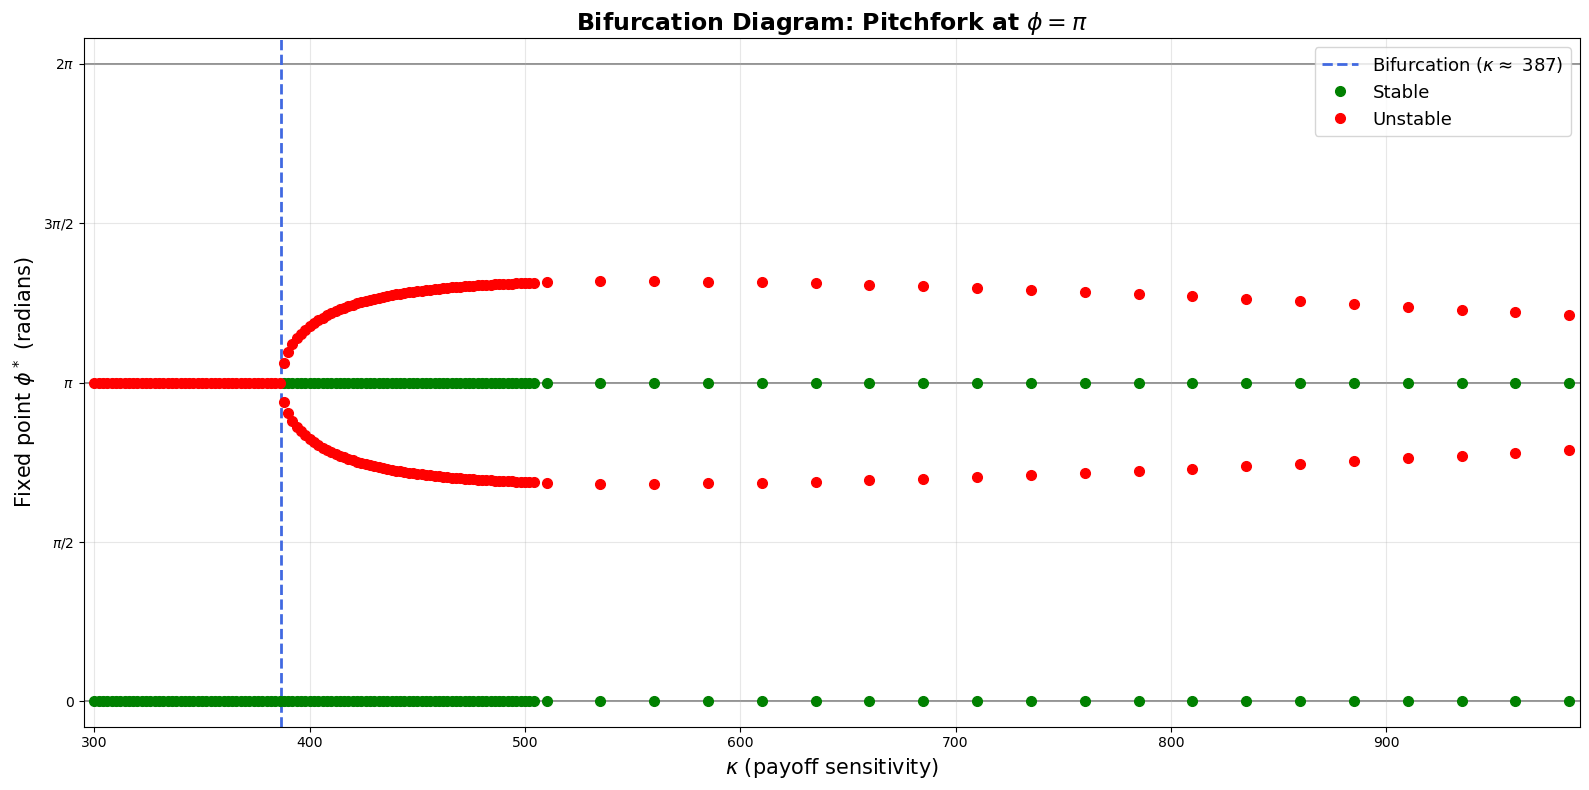

saved bifurcation_diagram.png and .pdf


In [2]:
# =============================================================================
# BIFURCATION DIAGRAM: fixed points of the phase equation vs kappa
# Self-contained. Saves bifurcation_diagram.png/.pdf and bifurcation_sweep.npz
# =============================================================================

import time
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.interpolate import interp1d, UnivariateSpline
from scipy.optimize import brentq


# -----------------------------------------------------------------------------
# System and Jacobian
# -----------------------------------------------------------------------------

def uncoupled_smooth_sirv(t, y, params):
    S, I, v = y
    alpha = params['alpha']
    beta  = params['beta']
    gamma = params['gamma']
    eta   = params['eta']
    theta = params['theta']
    kappa = params['kappa']
    rho   = params['rho']

    dS = alpha*(1 - S - I) - beta*S*I - eta*v*S
    dI = -gamma*I + beta*S*I
    dv = -v + 1/(1 + np.exp(-kappa*(beta*I - rho - theta*(1 - 2*v))))
    return [dS, dI, dv]


_S, _I, _v = sp.symbols('S I v')
_al, _be, _ga, _et = sp.symbols('alpha beta gamma eta')
_th, _ka, _rh = sp.symbols('theta kappa rho')

_F = sp.Matrix([
    _al*(1 - _S - _I) - _be*_S*_I - _et*_v*_S,
    -_ga*_I + _be*_S*_I,
    -_v + 1/(1 + sp.exp(-_ka*(_be*_I - _rh - _th*(1 - 2*_v))))
])
_DF_func = sp.lambdify((_S, _I, _v, _al, _be, _ga, _et, _th, _ka, _rh),
                       _F.jacobian(sp.Matrix([_S, _I, _v])), modules='numpy')


def compute_DF(S, I, v, params):
    return np.array(_DF_func(S, I, v,
                             params['alpha'], params['beta'], params['gamma'],
                             params['eta'], params['theta'], params['kappa'],
                             params['rho']))


def make_periodic_interp(t, y, T):
    t1, y1 = t[:-1], y[:-1]
    t_ext = np.concatenate([t1 - T, t1, t1 + T])
    y_ext = np.concatenate([y1, y1, y1])
    f = interp1d(t_ext, y_ext, kind='cubic')
    return lambda tq: f(np.mod(tq, T))


# -----------------------------------------------------------------------------
# One phase reduction, returning only what the sweep needs
# -----------------------------------------------------------------------------

def run_phase_reduction_sweep(params, n_points=4000, n_periods=10, n_phi=400,
                              y0=None, t_transient=500, t_cycle_search=800):
    """Returns (T, fixed_points, C'(0), C'(pi), |Z(T)-Z(0)|, warm-start state).

    phi is in radians throughout and C' is returned as a rate in day^-1.
    """

    if y0 is None:
        y0 = [0.49, 0.01, 0.01]

    # limit cycle
    sol_tr = solve_ivp(lambda t, y: uncoupled_smooth_sirv(t, y, params),
                       [0, t_transient], y0,
                       method='RK45', rtol=1e-10, atol=1e-12)

    dt = 0.01
    sol_s = solve_ivp(lambda t, y: uncoupled_smooth_sirv(t, y, params),
                      [0, t_cycle_search], sol_tr.y[:, -1], method='RK45',
                      t_eval=np.arange(0, t_cycle_search, dt),
                      rtol=1e-10, atol=1e-12)
    pk, _ = find_peaks(sol_s.y[1], height=np.mean(sol_s.y[1]),
                       distance=int(1/dt))
    T = np.mean(np.diff(sol_s.t[pk])[-5:])

    y_cycle_start = sol_s.y[:, pk[-2]]
    sol_c = solve_ivp(lambda t, y: uncoupled_smooth_sirv(t, y, params),
                      [0, T], y_cycle_start, method='RK45',
                      t_eval=np.linspace(0, T, n_points),
                      rtol=1e-12, atol=1e-14)

    t_cyc = sol_c.t
    S_c, I_c, v_c = sol_c.y

    # A(t) and gamma'(t)
    A = np.zeros((n_points, 3, 3))
    Gamma_dot = np.zeros((3, n_points))
    for i in range(n_points):
        A[i] = compute_DF(S_c[i], I_c[i], v_c[i], params)
        Gamma_dot[:, i] = uncoupled_smooth_sirv(t_cyc[i], sol_c.y[:, i],
                                                params)

    A_base = interp1d(t_cyc, A, axis=0, kind='linear',
                      fill_value='extrapolate')

    def adjoint_rhs(s, Z):
        return A_base(np.mod(T - (s % T), T)).T @ Z

    total = n_periods * T
    sol_a = solve_ivp(adjoint_rhs, [0, total], np.array([1.0, 1.0, 1.0]),
                      method='RK45',
                      t_eval=np.linspace(0, total, n_points*n_periods),
                      rtol=1e-10, atol=1e-12)

    Z_raw = sol_a.y[:, (n_periods - 1)*n_points:][:, ::-1]
    if Z_raw.shape[1] != n_points:
        t_raw = np.linspace(0, T, Z_raw.shape[1])
        Z_raw = np.vstack([np.interp(t_cyc, t_raw, Z_raw[i])
                           for i in range(3)])

    periodicity_err = np.linalg.norm(Z_raw[:, -1] - Z_raw[:, 0])
    Z_norm = Z_raw * (2*np.pi/T) / np.sum(Z_raw * Gamma_dot, axis=0)
    Z_v = Z_norm[2]

    # sigma'(xi) and H(phi)
    xi = params['kappa']*(params['beta']*I_c - params['rho']
                          - params['theta']*(1 - 2*v_c))
    sigma = 1/(1 + np.exp(-xi))
    sigma_prime = sigma*(1 - sigma)

    v_interp = make_periodic_interp(t_cyc, v_c, T)

    omega = 2*np.pi / T

    def compute_H(phi):
        # phi is in RADIANS; gamma is parametrized by time, so shift by phi/omega
        integrand = (Z_v * (-2) * params['kappa'] * params['theta']
                     * sigma_prime * (v_c - v_interp(t_cyc + phi/omega)))
        return np.trapz(integrand, t_cyc) / T

    phi_values = np.linspace(0, 2*np.pi, n_phi)
    H_values = np.array([compute_H(p) for p in phi_values])
    C_values = np.array([compute_H(-p) for p in phi_values]) - H_values

    # fixed points
    C_spline = UnivariateSpline(phi_values, C_values, s=0)
    C_deriv  = C_spline.derivative()

    roots = [0.0, np.pi, 2*np.pi]              # exact by oddness of C
    for idx in np.where(np.diff(np.sign(C_values)))[0]:
        try:
            roots.append(brentq(C_spline, phi_values[idx], phi_values[idx+1]))
        except Exception:
            pass

    fixed_points = []
    for r in sorted(roots):
        if fixed_points and abs(r - fixed_points[-1][0]) < 1e-6:
            continue
        d = float(C_deriv(2*np.pi if r == 0.0 else r))
        fixed_points.append((r, r, d, d < 0))   # r is already in radians

    return (T, fixed_points, float(C_deriv(2*np.pi)), float(C_deriv(np.pi)),
            periodicity_err, y_cycle_start)


# -----------------------------------------------------------------------------
# Sweep
# -----------------------------------------------------------------------------

base_params = {
    'alpha': 0.01,
    'beta':  0.5,
    'gamma': 1/7,
    'eta':   1/7,
    'theta': 0.01,
    'rho':   0.01,
}

kappa_values = np.concatenate([np.arange(300, 506, 2),     # dense
                               np.arange(510, 1001, 25)])  # sparse

kap_flat, phi_flat, stab_flat = [], [], []
Cp_0_list, Cp_pi_list, T_list, err_list = [], [], [], []

warm = None
t0 = time.time()

for j, kappa in enumerate(kappa_values):
    p = dict(base_params, kappa=float(kappa))
    T, fps, Cp_0, Cp_pi, err, warm = run_phase_reduction_sweep(
        p, y0=(None if warm is None else list(warm)))

    for phi, theta, _, stable in fps:
        if abs(phi - 2*np.pi) < 1e-6:
            continue                            # phi = 2*pi duplicates phi = 0
        kap_flat.append(kappa)
        phi_flat.append(theta)
        stab_flat.append(stable)

    Cp_0_list.append(Cp_0)
    Cp_pi_list.append(Cp_pi)
    T_list.append(T)
    err_list.append(err)

    print(f"[{j+1:3d}/{len(kappa_values)}] kappa = {kappa:6.1f}   "
          f"T = {T:7.3f}   C'(pi) = {Cp_pi:+.4e} /day   "
          f"{len(fps)-1} fixed pts   {time.time()-t0:6.1f}s", flush=True)

kap_flat  = np.array(kap_flat, dtype=float)
phi_flat  = np.array(phi_flat)
stab_flat = np.array(stab_flat, dtype=bool)
Cp_pi_arr = np.array(Cp_pi_list)

# pitchfork location: sign change of C'(pi), linearly interpolated
kappa_star = None
cross = np.where(np.diff(np.sign(Cp_pi_arr)) != 0)[0]
if len(cross):
    i = cross[0]
    k0, k1 = kappa_values[i], kappa_values[i+1]
    c0, c1 = Cp_pi_arr[i], Cp_pi_arr[i+1]
    kappa_star = k0 - c0*(k1 - k0)/(c1 - c0)
    print(f"\nPitchfork at kappa* = {kappa_star:.2f} "
          f"(bracketed by {k0:.0f} and {k1:.0f})")
else:
    print("\nNo sign change in C'(pi) over the sweep.")

print(f"max |Z(T) - Z(0)| over sweep: {max(err_list):.3e}")

np.savez('bifurcation_sweep.npz',
         kappa_values=kappa_values, Cp_0=np.array(Cp_0_list), Cp_pi=Cp_pi_arr,
         T=np.array(T_list), periodicity_err=np.array(err_list),
         kap_flat=kap_flat, phi_flat=phi_flat, stab_flat=stab_flat,
         kappa_star=(np.nan if kappa_star is None else kappa_star))
print("saved bifurcation_sweep.npz")


# -----------------------------------------------------------------------------
# Figure
# -----------------------------------------------------------------------------

TICKS  = [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi]
LABELS = ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$']

fig, ax = plt.subplots(figsize=(16, 8))

for level in (0, np.pi, 2*np.pi):
    ax.axhline(level, color='gray', linewidth=1.2, zorder=1)

if kappa_star is not None:
    ax.axvline(kappa_star, color='royalblue', linestyle='--', linewidth=2,
               zorder=2,
               label=rf'Bifurcation ($\kappa \approx$ {kappa_star:.0f})')

ax.plot(kap_flat[stab_flat], phi_flat[stab_flat], 'o', color='green',
        markersize=7, linestyle='', zorder=3, label='Stable')
ax.plot(kap_flat[~stab_flat], phi_flat[~stab_flat], 'o', color='red',
        markersize=7, linestyle='', zorder=3, label='Unstable')

ax.set_xlabel(r'$\kappa$ (payoff sensitivity)', fontsize=15)
ax.set_ylabel(r'Fixed point $\phi^*$ (radians)', fontsize=15)
ax.set_title(r'Bifurcation Diagram: Pitchfork at $\phi = \pi$',
             fontsize=17, fontweight='bold')

ax.set_ylim(-0.25, 2*np.pi + 0.25)
ax.set_yticks(TICKS)
ax.set_yticklabels(LABELS)
ax.set_xlim(kappa_values.min() - 5, kappa_values.max() + 5)
ax.grid(True, alpha=0.3)

h, l = ax.get_legend_handles_labels()
seen, hh, ll = set(), [], []
for hi, li in zip(h, l):
    if li not in seen:
        seen.add(li); hh.append(hi); ll.append(li)
ax.legend(hh, ll, fontsize=13, loc='upper right')

plt.tight_layout()
plt.savefig('bifurcation_diagram.png', dpi=300, bbox_inches='tight')
plt.savefig('bifurcation_diagram.pdf', bbox_inches='tight')
plt.show()

print("saved bifurcation_diagram.png and .pdf")